In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

# Data Understanding

In [2]:
mat = pd.read_csv('D:\Coding\Bleep\Resources\student+performance\student-mat.csv', sep=';')
por = pd.read_csv('D:\Coding\Bleep\Resources\student+performance\student-por.csv', sep=';')
print("Math:", mat.shape, "| Portuguese:", por.shape)
mat.head()

Math: (395, 33) | Portuguese: (649, 33)


<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:2: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:2: SyntaxWarning: invalid escape sequence '\C'
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_20360\3947085590.py:1: SyntaxWarning: invalid escape sequence '\C'
  mat = pd.read_csv('D:\Coding\Bleep\Resources\student+performance\student-mat.csv', sep=';')
C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_20360\3947085590.py:2: SyntaxWarning: invalid escape sequence '\C'
  por = pd.read_csv('D:\Coding\Bleep\Resources\student+performance\student-por.csv', sep=';')


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
mat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

# Data Cleaning

`G1` and `G2` are stored as quoted strings in the raw files, so they are cast to integers.

In [4]:
for d in (mat, por):
    d[['G1', 'G2']] = d[['G1', 'G2']].astype(int)

for name, d in [('math', mat), ('portuguese', por)]:
    print(name, "| missing:", int(d.isna().sum().sum()), "| duplicates:", int(d.duplicated().sum()),
          "| constant columns:", [c for c in d if d[c].nunique() == 1],
          "| grade range:", d[['G1', 'G2', 'G3']].min().min(), "-", d[['G1', 'G2', 'G3']].max().max())

math | missing: 0 | duplicates: 0 | constant columns: [] | grade range: 0 - 20
portuguese | missing: 0 | duplicates: 0 | constant columns: [] | grade range: 0 - 19


In [5]:
keys = ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
        'Mjob', 'Fjob', 'reason', 'nursery', 'internet']
print("Students enrolled in both subjects:", len(mat.merge(por, on=keys)))

Students enrolled in both subjects: 382


In [6]:
mat['subject'] = 'Math'
por['subject'] = 'Portuguese'
df = pd.concat([mat, por], ignore_index=True)

df = df.rename(columns={
    "Medu": "mother_edu", "Fedu": "father_edu", "Mjob": "mother_job", "Fjob": "father_job",
    "Pstatus": "parent_status", "famsize": "family_size", "studytime": "study_time",
    "traveltime": "travel_time", "famsup": "family_support", "schoolsup": "school_support",
    "activities": "extracurricular", "higher": "wants_higher_edu", "famrel": "family_relation",
    "freetime": "free_time", "goout": "go_out", "Dalc": "weekday_alcohol", "Walc": "weekend_alcohol",
    "G1": "g1", "G2": "g2", "G3": "g3"})

EDU = {0: "None", 1: "Primary", 2: "5th-9th", 3: "Secondary", 4: "Higher"}
STUDY = {1: "<2h", 2: "2-5h", 3: "5-10h", 4: ">10h"}

df["mother_edu_label"] = pd.Categorical(df.mother_edu.map(EDU), categories=list(EDU.values()), ordered=True)
df["father_edu_label"] = pd.Categorical(df.father_edu.map(EDU), categories=list(EDU.values()), ordered=True)
df["study_label"] = pd.Categorical(df.study_time.map(STUDY), categories=list(STUDY.values()), ordered=True)
df["grade_band"] = pd.cut(df.g3, [-1, 9, 13, 16, 20],
                          labels=["Fail (0-9)", "Pass (10-13)", "Good (14-16)", "Excellent (17-20)"])
df["absence_band"] = pd.cut(df.absences, [-1, 0, 4, 10, 20, 100], labels=["0", "1-4", "5-10", "11-20", "21+"])
df["parent_edu"] = (df.mother_edu + df.father_edu) / 2
df["passed"] = (df.g3 >= 10).astype(int)
df["zero_grade"] = df.g3 == 0
df["grade_change"] = df.g3 - df.g1

print(df.shape)
df.head()

(1044, 43)


,school,sex,age,address,family_size,parent_status,mother_edu,father_edu,mother_job,father_job,...,subject,mother_edu_label,father_edu_label,study_label,grade_band,absence_band,parent_edu,passed,zero_grade,grade_change
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,Math,Higher,Higher,2-5h,Fail (0-9),5-10,4.0,0,False,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,Math,Primary,Primary,2-5h,Fail (0-9),1-4,1.0,0,False,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,Math,Primary,Primary,2-5h,Pass (10-13),5-10,1.0,1,False,3
3,GP,F,15,U,GT3,T,4,2,health,services,...,Math,Higher,5th-9th,5-10h,Good (14-16),1-4,3.0,1,False,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,Math,Secondary,Secondary,2-5h,Pass (10-13),1-4,3.0,1,False,4


# Descriptive Statistics

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.73,1.24,15.0,16.0,17.0,18.0,22.0
mother_edu,1044.0,2.60,1.12,0.0,2.0,3.0,4.0,4.0
father_edu,1044.0,2.39,1.10,0.0,1.0,2.0,3.0,4.0
travel_time,1044.0,1.52,0.73,1.0,1.0,1.0,2.0,4.0
study_time,1044.0,1.97,0.83,1.0,1.0,2.0,2.0,4.0
failures,1044.0,0.26,0.66,0.0,0.0,0.0,0.0,3.0
family_relation,1044.0,3.94,0.93,1.0,4.0,4.0,5.0,5.0
free_time,1044.0,3.20,1.03,1.0,3.0,3.0,4.0,5.0
go_out,1044.0,3.16,1.15,1.0,2.0,3.0,4.0,5.0
weekday_alcohol,1044.0,1.49,0.91,1.0,1.0,1.0,2.0,5.0


In [8]:
df.select_dtypes(['object', 'string']).describe().T

,count,unique,top,freq
school,1044,2,GP,772
sex,1044,2,F,591
address,1044,2,U,759
family_size,1044,2,GT3,738
parent_status,1044,2,T,923
mother_job,1044,5,other,399
father_job,1044,5,other,584
reason,1044,4,course,430
guardian,1044,3,mother,728
school_support,1044,2,no,925


In [9]:
df.groupby('subject')[['g1', 'g2', 'g3', 'absences', 'study_time', 'failures']].agg(['mean', 'median', 'std']).round(2).T

subject             Math  Portuguese
g1         mean    10.91       11.40
           median  11.00       11.00
           std      3.32        2.75
g2         mean    10.71       11.57
           median  11.00       11.00
           std      3.76        2.91
g3         mean    10.42       11.91
           median  11.00       12.00
           std      4.58        3.23
absences   mean     5.71        3.66
           median   4.00        2.00
           std      8.00        4.64
study_time mean     2.04        1.93
           median   2.00        2.00
           std      0.84        0.83
failures   mean     0.33        0.22
           median   0.00        0.00
           std      0.74        0.59

# Exploratory Analysis

## 1. Distribution of Final Grades

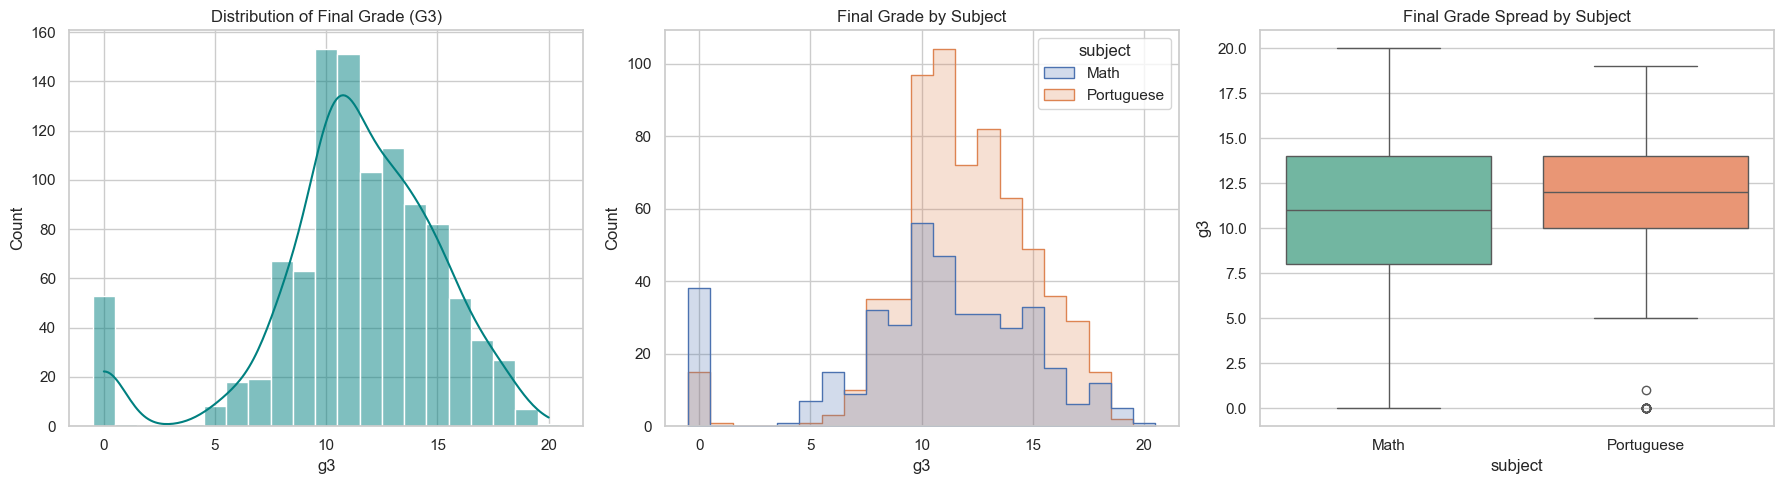

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df.g3, bins=21, discrete=True, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Final Grade (G3)')

sns.histplot(data=df, x='g3', hue='subject', discrete=True, element='step', ax=axes[1])
axes[1].set_title('Final Grade by Subject')

sns.boxplot(data=df, x='subject', y='g3', hue='subject', palette='Set2', ax=axes[2])
axes[2].set_title('Final Grade Spread by Subject')
plt.tight_layout()
plt.show()

In [11]:
print(df.g3.describe().round(2))
print("Skewness:", round(df.g3.skew(), 2), "| Kurtosis:", round(df.g3.kurt(), 2))
print("\nPass rate (G3 >= 10):", round(df.passed.mean() * 100, 1), "%")
print("\nShare of students per grade band (%):")
print(pd.crosstab(df.subject, df.grade_band, normalize='index').mul(100).round(1))
print("\nZero grades:", df.groupby('subject').zero_grade.sum().to_dict())
print("Math vs Portuguese Mann-Whitney p-value:", stats.mannwhitneyu(df[df.subject == 'Math'].g3, df[df.subject == 'Portuguese'].g3).pvalue)

count    1044.00
mean       11.34
std         3.86
min         0.00
25%        10.00
50%        11.00
75%        14.00
max        20.00
Name: g3, dtype: float64
Skewness: -0.99 | Kurtosis: 1.74

Pass rate (G3 >= 10): 78.0 %

Share of students per grade band (%):
grade_band  Fail (0-9)  Pass (10-13)  Good (14-16)  Excellent (17-20)
subject                                                              
Math              32.9          41.8          19.2                6.1
Portuguese        15.4          54.7          22.8                7.1

Zero grades: {'Math': 38, 'Portuguese': 15}
Math vs Portuguese Mann-Whitney p-value: 1.9477574100362618e-07


**Findings**
- The final grade distribution is left-skewed (skewness -0.99) with a median of 11/20; 78% of enrolments pass (G3 >= 10).
- Portuguese grades are higher and tighter (mean 11.9, SD 3.2) than Math (mean 10.4, SD 4.6); the gap is statistically significant.
- A spike at 0 (53 records, 38 in Math) comes from students who did not finish the course, not from low ability.

## 2. Study Time vs Performance

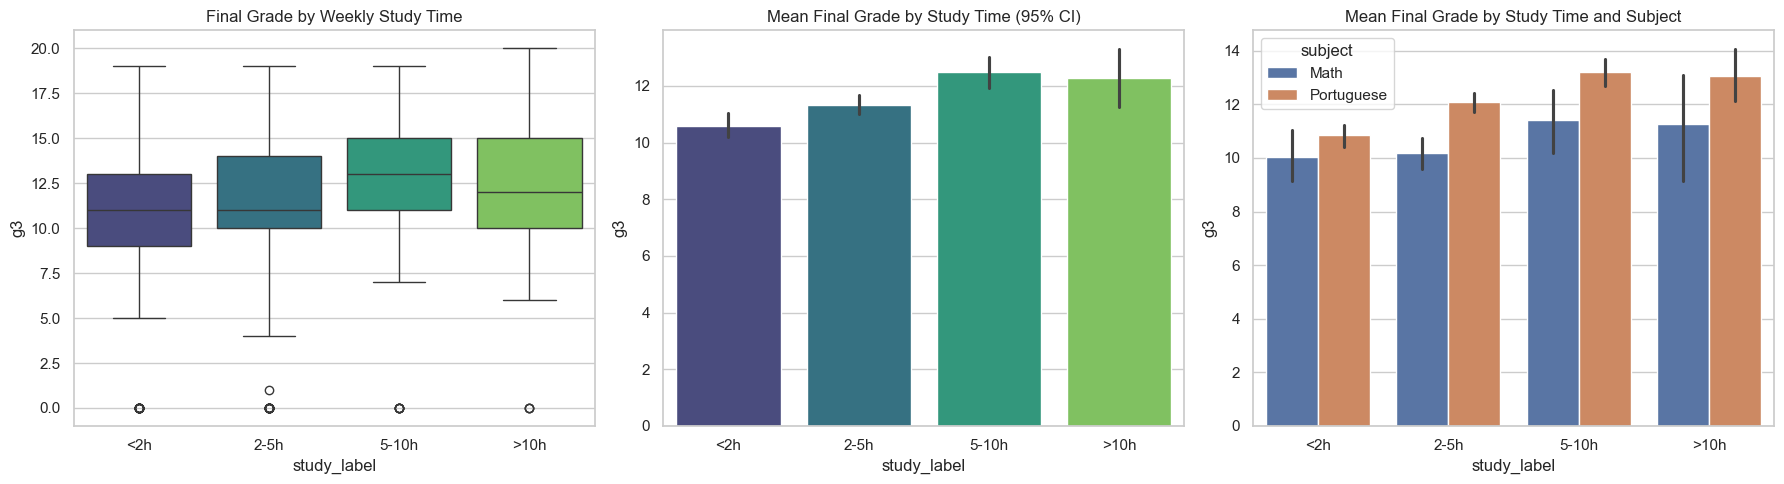

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x='study_label', y='g3', hue='study_label', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Final Grade by Weekly Study Time')

sns.barplot(data=df, x='study_label', y='g3', hue='study_label', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Mean Final Grade by Study Time (95% CI)')

sns.barplot(data=df, x='study_label', y='g3', hue='subject', ax=axes[2])
axes[2].set_title('Mean Final Grade by Study Time and Subject')
plt.tight_layout()
plt.show()

In [13]:
print(df.groupby('study_label').g3.agg(['count', 'mean', 'median']).round(2))
print("\nSpearman (all):", round(df.study_time.corr(df.g3, method='spearman'), 3))
for s, d in df.groupby('subject'):
    print(f"Spearman ({s}):", round(d.study_time.corr(d.g3, method='spearman'), 3))
print("Kruskal-Wallis p-value:", stats.kruskal(*[g.g3 for _, g in df.groupby('study_time')]).pvalue)

             count   mean  median
study_label                      
<2h            317  10.58    11.0
2-5h           503  11.34    11.0
5-10h          162  12.49    13.0
>10h            62  12.27    12.0

Spearman (all): 0.19
Spearman (Math): 0.105
Spearman (Portuguese): 0.275
Kruskal-Wallis p-value: 1.0140685862603782e-08


C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_20360\2867265541.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('study_label').g3.agg(['count', 'mean', 'median']).round(2))


**Findings**
- Mean grade rises from 10.6 (<2h) to 12.5 (5-10h); beyond 10h it flattens (12.3), so returns diminish.
- The relationship is moderate (Spearman 0.19), stronger in Portuguese (0.28) than in Math (0.11).

## 3. Attendance vs Grades

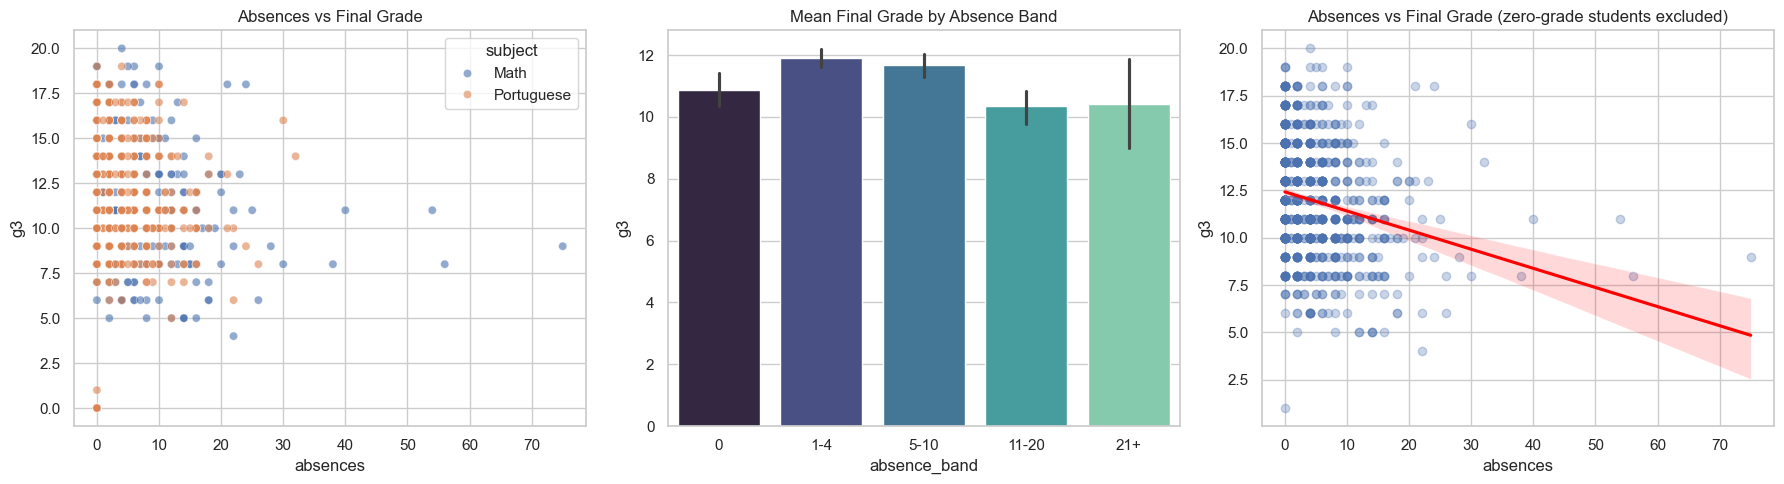

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x='absences', y='g3', hue='subject', alpha=0.6, ax=axes[0])
axes[0].set_title('Absences vs Final Grade')

sns.barplot(data=df, x='absence_band', y='g3', hue='absence_band', palette='mako', legend=False, ax=axes[1])
axes[1].set_title('Mean Final Grade by Absence Band')

active = df[~df.zero_grade]
sns.regplot(data=active, x='absences', y='g3', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'}, ax=axes[2])
axes[2].set_title('Absences vs Final Grade (zero-grade students excluded)')
plt.tight_layout()
plt.show()

In [15]:
print("Spearman (all):", round(df.absences.corr(df.g3, method='spearman'), 3))
print("Spearman (excluding zero grades):", round(active.absences.corr(active.g3, method='spearman'), 3))
for s, d in active.groupby('subject'):
    print(f"Spearman ({s}, excluding zero grades):", round(d.absences.corr(d.g3, method='spearman'), 3))
print("\nAbsences recorded for zero-grade students:", df[df.zero_grade].absences.value_counts().to_dict())
print("\nMean G3 by absence band (excluding zero grades):")
print(active.groupby('absence_band').g3.agg(['count', 'mean']).round(2))

Spearman (all): -0.109
Spearman (excluding zero grades): -0.238
Spearman (Math, excluding zero grades): -0.244
Spearman (Portuguese, excluding zero grades): -0.214

Absences recorded for zero-grade students: {0: 53}

Mean G3 by absence band (excluding zero grades):
              count   mean
absence_band              
0               306  12.77
1-4             351  11.92
5-10            219  11.68
11-20            92  10.35
21+              23  10.43


C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_20360\1114587120.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(active.groupby('absence_band').g3.agg(['count', 'mean']).round(2))


**Findings**
- Raw correlation between absences and grade is weak (-0.11) because every zero-grade student has 0 recorded absences.
- Excluding them, the relationship is clearly negative (-0.24): mean grade falls from 12.8 (no absences) to about 10.4 (11+ absences).

## 4. Parental Education vs Performance

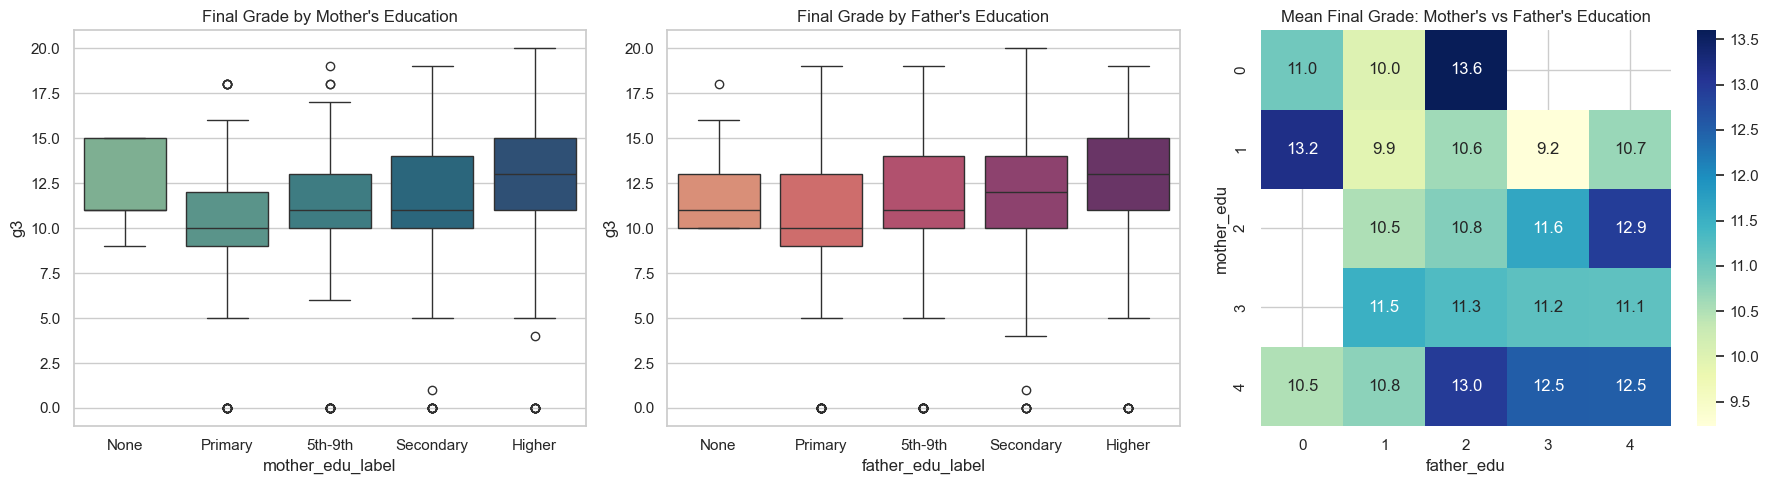

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x='mother_edu_label', y='g3', hue='mother_edu_label', palette='crest', legend=False, ax=axes[0])
axes[0].set_title("Final Grade by Mother's Education")

sns.boxplot(data=df, x='father_edu_label', y='g3', hue='father_edu_label', palette='flare', legend=False, ax=axes[1])
axes[1].set_title("Final Grade by Father's Education")

sns.heatmap(df.pivot_table(index='mother_edu', columns='father_edu', values='g3', aggfunc='mean'),
            annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[2])
axes[2].set_title("Mean Final Grade: Mother's vs Father's Education")
plt.tight_layout()
plt.show()

In [17]:
print("Spearman with G3 -> mother:", round(df.mother_edu.corr(df.g3, method='spearman'), 3),
      "| father:", round(df.father_edu.corr(df.g3, method='spearman'), 3),
      "| average:", round(df.parent_edu.corr(df.g3, method='spearman'), 3))
print("Kruskal-Wallis p-value (mother):", stats.kruskal(*[g.g3 for _, g in df.groupby('mother_edu')]).pvalue)
print("Kruskal-Wallis p-value (father):", stats.kruskal(*[g.g3 for _, g in df.groupby('father_edu')]).pvalue)
print()
print(df.groupby('mother_edu_label').agg(students=('g3', 'size'), mean_g3=('g3', 'mean'), pass_rate=('passed', 'mean')).round(2))

Spearman with G3 -> mother: 0.238 | father: 0.19 | average: 0.235
Kruskal-Wallis p-value (mother): 7.259276013552641e-14
Kruskal-Wallis p-value (father): 1.6513062290715628e-08

                  students  mean_g3  pass_rate
mother_edu_label                              
None                     9    12.11       0.89
Primary                202    10.18       0.69
5th-9th                289    10.97       0.78
Secondary              238    11.25       0.76
Higher                 306    12.51       0.85


C:\Users\VINAY DHIMAN\AppData\Local\Temp\ipykernel_20360\2939102531.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('mother_edu_label').agg(students=('g3', 'size'), mean_g3=('g3', 'mean'), pass_rate=('passed', 'mean')).round(2))


**Findings**
- Both parents' education are positively related to grades (mother 0.24, father 0.19); mother's education is the stronger of the two.
- Students whose mother has higher education average 12.5, versus 10.2 for primary-level education.
- The 9 students with uneducated mothers are too few to interpret.

## 5. Family Background vs Academic Outcomes

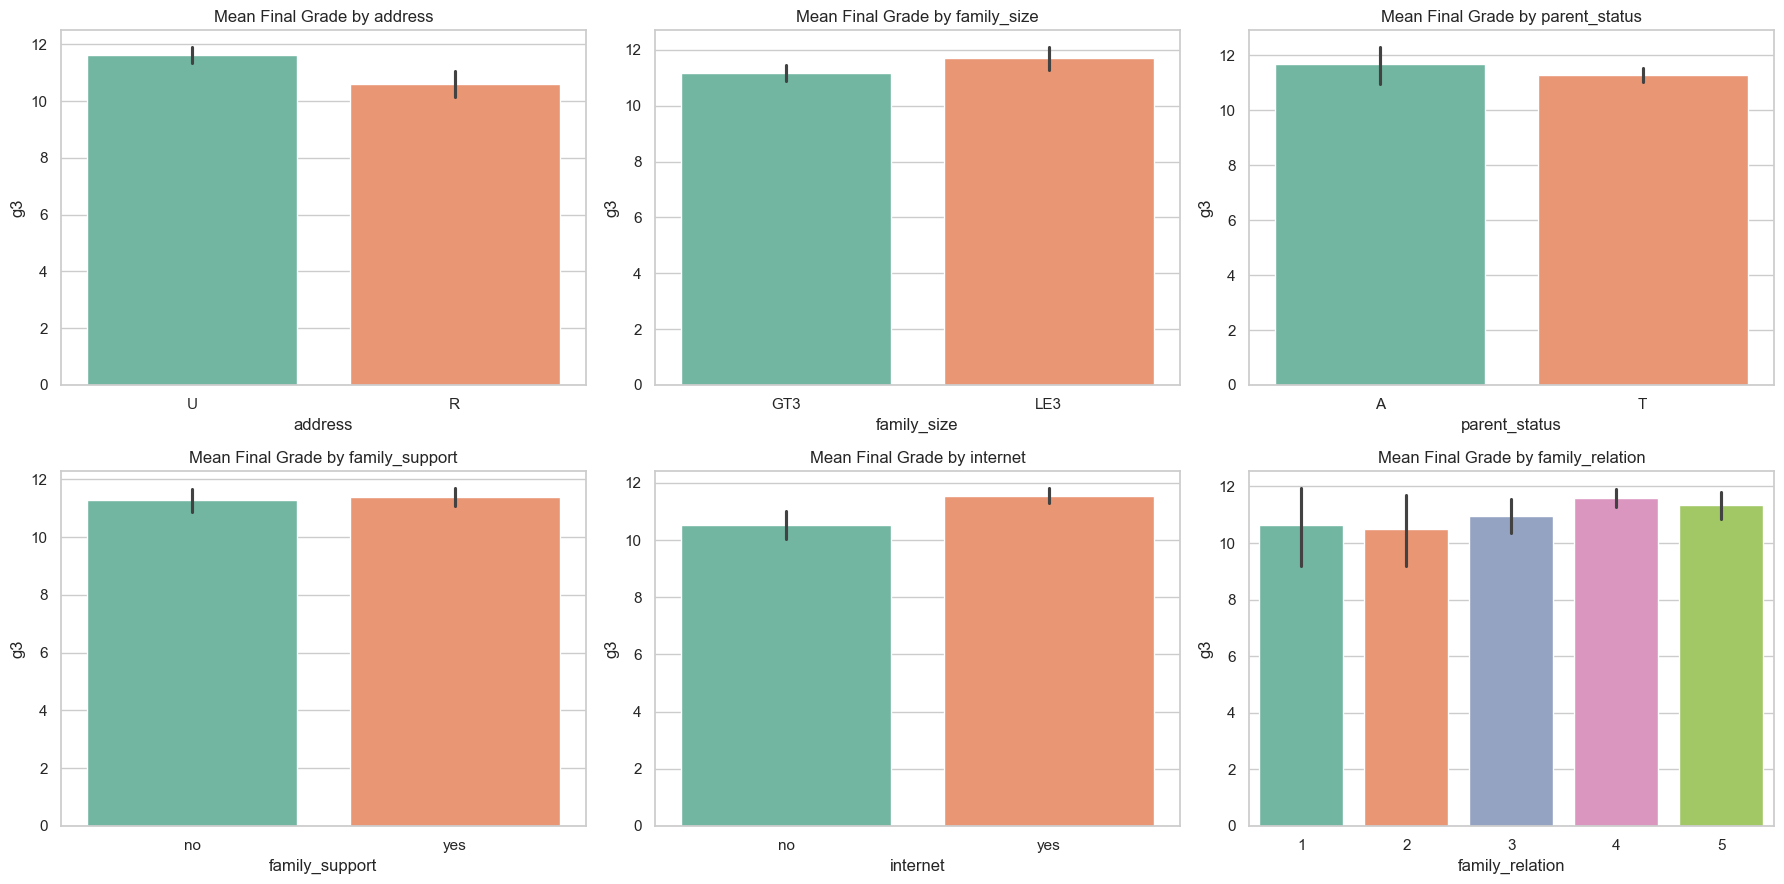

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), ['address', 'family_size', 'parent_status', 'family_support', 'internet', 'family_relation']):
    sns.barplot(data=df, x=col, y='g3', hue=col, palette='Set2', legend=False, ax=ax)
    ax.set_title(f'Mean Final Grade by {col}')
plt.tight_layout()
plt.show()

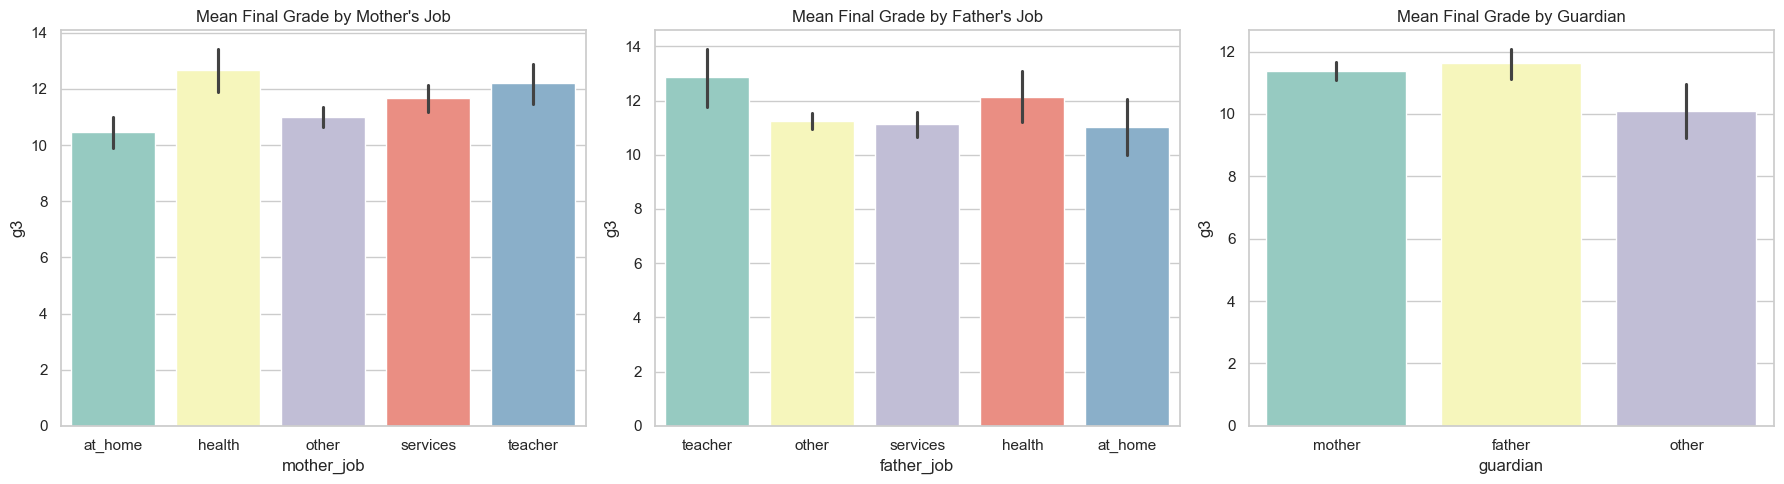

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=df, x='mother_job', y='g3', hue='mother_job', palette='Set3', legend=False, ax=axes[0])
axes[0].set_title("Mean Final Grade by Mother's Job")
sns.barplot(data=df, x='father_job', y='g3', hue='father_job', palette='Set3', legend=False, ax=axes[1])
axes[1].set_title("Mean Final Grade by Father's Job")
sns.barplot(data=df, x='guardian', y='g3', hue='guardian', palette='Set3', legend=False, ax=axes[2])
axes[2].set_title('Mean Final Grade by Guardian')
plt.tight_layout()
plt.show()

In [20]:
def compare(col):
    a, b = sorted(df[col].unique())
    x, y = df[df[col] == a].g3, df[df[col] == b].g3
    pooled = np.sqrt(((len(x) - 1) * x.var() + (len(y) - 1) * y.var()) / (len(x) + len(y) - 2))
    return pd.Series({"groups": f"{a} vs {b}", "mean_a": x.mean(), "mean_b": y.mean(),
                      "diff": y.mean() - x.mean(), "cohens_d": (y.mean() - x.mean()) / pooled,
                      "p_value": stats.mannwhitneyu(x, y).pvalue})

family_tests = pd.DataFrame({c: compare(c) for c in ['address', 'family_size', 'parent_status', 'family_support', 'internet']}).T
family_tests[['mean_a', 'mean_b', 'diff', 'cohens_d', 'p_value']] = family_tests[['mean_a', 'mean_b', 'diff', 'cohens_d', 'p_value']].astype(float)
print(family_tests.to_string(formatters={'mean_a': '{:.2f}'.format, 'mean_b': '{:.2f}'.format, 'diff': '{:.2f}'.format,
                                          'cohens_d': '{:.2f}'.format, 'p_value': '{:.4f}'.format}))
print()
for c in ['mother_job', 'father_job', 'guardian', 'family_relation']:
    print(f"Kruskal-Wallis p-value ({c}):", format(stats.kruskal(*[g.g3 for _, g in df.groupby(c)]).pvalue, '.4f'))

                    groups mean_a mean_b  diff cohens_d p_value
address             R vs U  10.60  11.62  1.02     0.27  0.0000
family_size     GT3 vs LE3  11.19  11.71  0.52     0.13  0.2105
parent_status       A vs T  11.67  11.30 -0.37    -0.10  0.4585
family_support   no vs yes  11.28  11.38  0.11     0.03  0.9622
internet         no vs yes  10.53  11.55  1.02     0.27  0.0001

Kruskal-Wallis p-value (mother_job): 0.0000
Kruskal-Wallis p-value (father_job): 0.0005
Kruskal-Wallis p-value (guardian): 0.0022
Kruskal-Wallis p-value (family_relation): 0.2091


**Findings**
- Urban address and home internet access each add about 1 grade point (Cohen's d about 0.27, both significant).
- Family size, parents' cohabitation status and family educational support show no significant difference.
- Parental occupation matters modestly: children of teachers and health workers score highest, children of stay-at-home mothers lowest.
- Family background shows up mainly through resources and parental education, not household structure.

## 6. Previous Academic Performance vs Final Grade

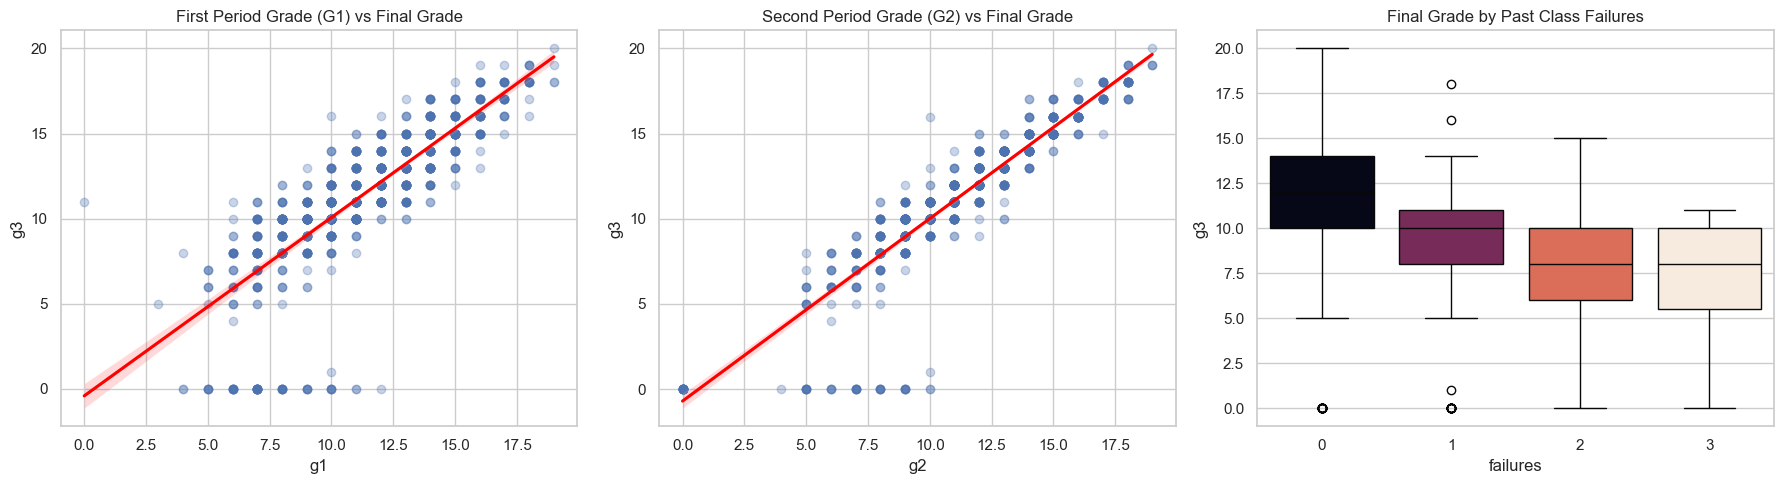

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.regplot(data=df, x='g1', y='g3', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('First Period Grade (G1) vs Final Grade')

sns.regplot(data=df, x='g2', y='g3', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title('Second Period Grade (G2) vs Final Grade')

sns.boxplot(data=df, x='failures', y='g3', hue='failures', palette='rocket', legend=False, ax=axes[2])
axes[2].set_title('Final Grade by Past Class Failures')
plt.tight_layout()
plt.show()

In [22]:
print(df[['g1', 'g2', 'g3']].corr().round(3))
print("\nSpearman failures vs G3:", round(df.failures.corr(df.g3, method='spearman'), 3))
print(df.groupby('failures').agg(students=('g3', 'size'), mean_g3=('g3', 'mean'), pass_rate=('passed', 'mean')).round(2))
print("\nFinal grade within +/-2 points of G2:", round((df.g3 - df.g2).abs().le(2).mean() * 100, 1), "%")
print("Mean change G1 -> G3 by subject:", df.groupby('subject').grade_change.mean().round(2).to_dict())

       g1     g2     g3
g1  1.000  0.859  0.809
g2  0.859  1.000  0.911
g3  0.809  0.911  1.000

Spearman failures vs G3: -0.413
          students  mean_g3  pass_rate
failures                              
0              861    12.05       0.85
1              120     8.43       0.52
2               33     7.48       0.33
3               30     6.80       0.30

Final grade within +/-2 points of G2: 95.3 %
Mean change G1 -> G3 by subject: {'Math': -0.49, 'Portuguese': 0.51}


**Findings**
- Earlier grades are the strongest predictor: G3 correlates 0.81 with G1 and 0.91 with G2, and 95% of final grades land within 2 points of G2.
- Each past class failure sharply lowers outcomes: mean grade 12.1 with no failures versus 8.4 with one; pass rate drops from 85% to 52%.
- Math grades drift down from G1 to G3 (-0.5 on average) while Portuguese grades drift up (+0.5).

## 7. Extracurricular Activities vs Performance

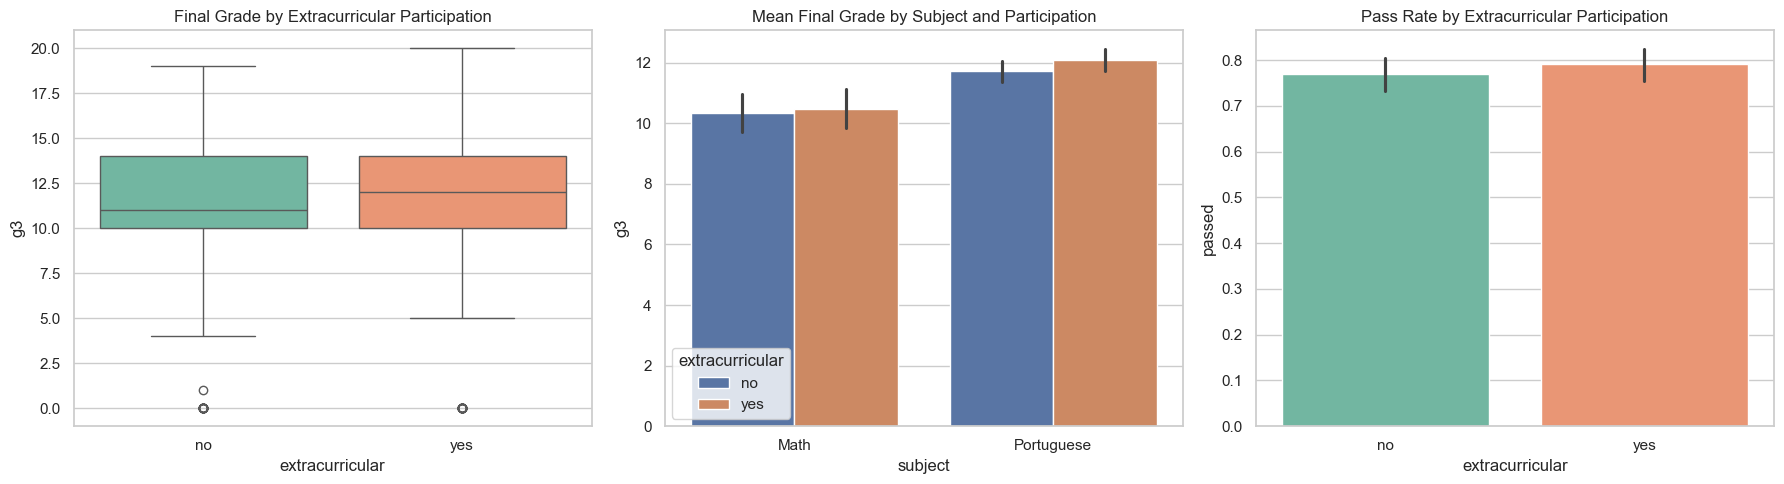

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x='extracurricular', y='g3', hue='extracurricular', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Final Grade by Extracurricular Participation')

sns.barplot(data=df, x='subject', y='g3', hue='extracurricular', ax=axes[1])
axes[1].set_title('Mean Final Grade by Subject and Participation')

sns.barplot(data=df, x='extracurricular', y='passed', hue='extracurricular', palette='Set2', legend=False, ax=axes[2])
axes[2].set_title('Pass Rate by Extracurricular Participation')
plt.tight_layout()
plt.show()

In [24]:
print(df.groupby('extracurricular').agg(students=('g3', 'size'), mean_g3=('g3', 'mean'), pass_rate=('passed', 'mean')).round(3))
print("\nMann-Whitney p-value (all):", round(stats.mannwhitneyu(df[df.extracurricular == 'yes'].g3, df[df.extracurricular == 'no'].g3).pvalue, 4))
for s, d in df.groupby('subject'):
    print(f"Mann-Whitney p-value ({s}):", round(stats.mannwhitneyu(d[d.extracurricular == 'yes'].g3, d[d.extracurricular == 'no'].g3).pvalue, 4))

                 students  mean_g3  pass_rate
extracurricular                              
no                    528   11.212      0.769
yes                   516   11.475      0.791

Mann-Whitney p-value (all): 0.0807
Mann-Whitney p-value (Math): 0.6049
Mann-Whitney p-value (Portuguese): 0.0369


## 8. Gender Differences

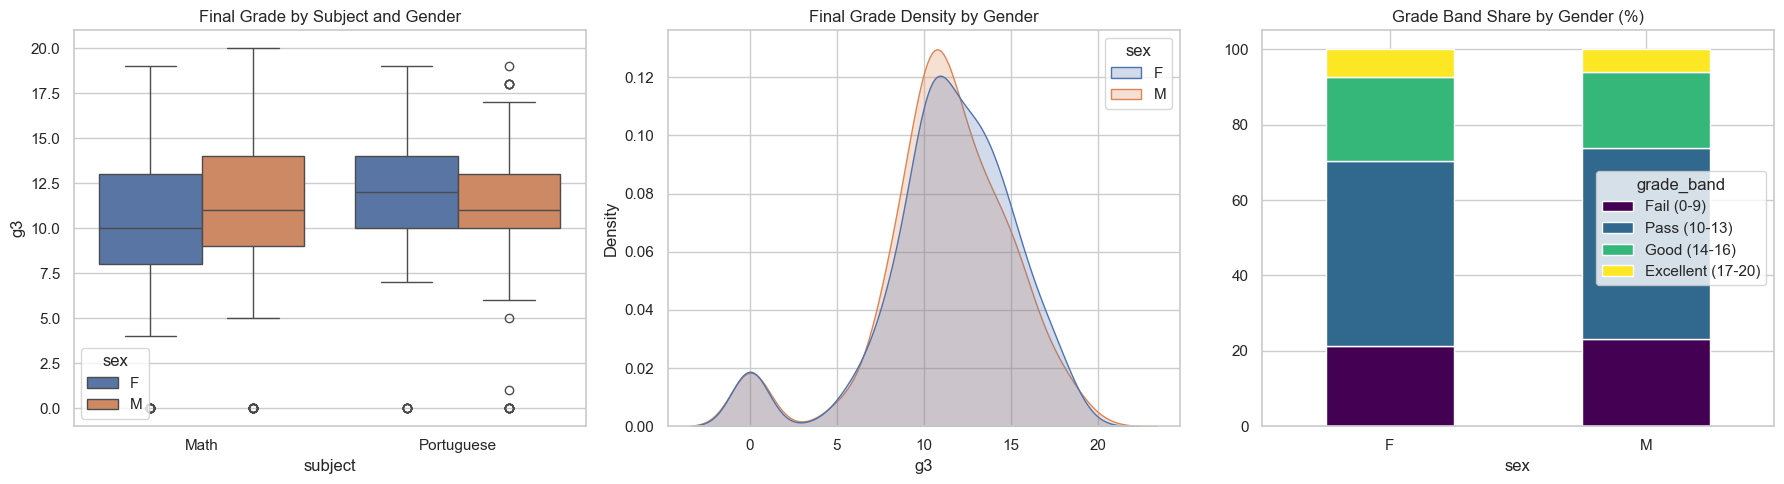

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x='subject', y='g3', hue='sex', ax=axes[0])
axes[0].set_title('Final Grade by Subject and Gender')

sns.kdeplot(data=df, x='g3', hue='sex', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Final Grade Density by Gender')

(pd.crosstab(df.sex, df.grade_band, normalize='index') * 100).plot(kind='bar', stacked=True, colormap='viridis', ax=axes[2])
axes[2].set_title('Grade Band Share by Gender (%)')
axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [26]:
print(df.groupby(['subject', 'sex']).agg(students=('g3', 'size'), mean_g3=('g3', 'mean'), pass_rate=('passed', 'mean')).round(2))
print("\nMann-Whitney p-value (all):", round(stats.mannwhitneyu(df[df.sex == 'F'].g3, df[df.sex == 'M'].g3).pvalue, 4))
for s, d in df.groupby('subject'):
    print(f"Mann-Whitney p-value ({s}):", round(stats.mannwhitneyu(d[d.sex == 'F'].g3, d[d.sex == 'M'].g3).pvalue, 4))

                students  mean_g3  pass_rate
subject    sex                              
Math       F         208     9.97       0.64
           M         187    10.91       0.71
Portuguese F         383    12.25       0.87
           M         266    11.41       0.81

Mann-Whitney p-value (all): 0.1477
Mann-Whitney p-value (Math): 0.0407
Mann-Whitney p-value (Portuguese): 0.0006


## 9. Factors Most Strongly Related to Final Grade

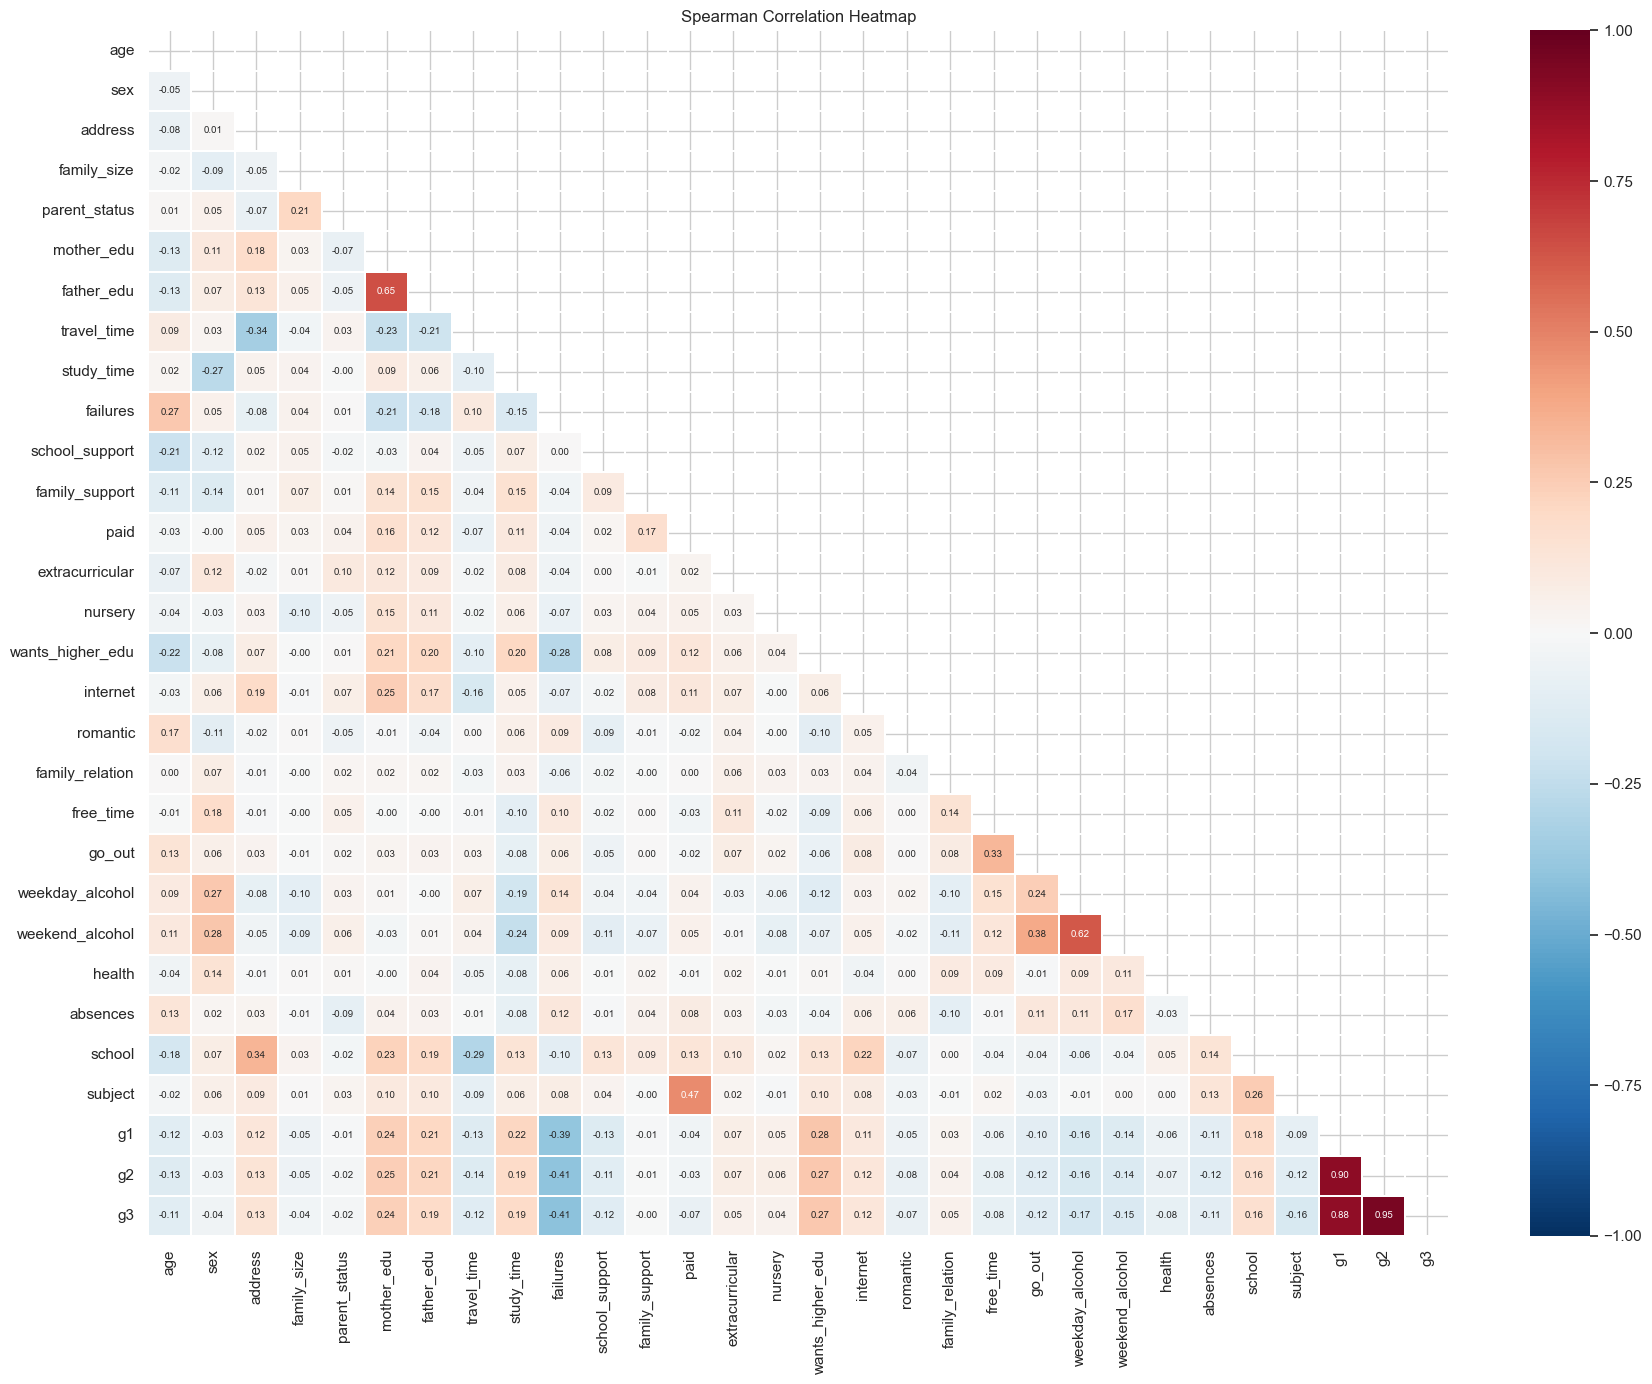

In [27]:
enc = df.copy()
yes_no = ['school_support', 'family_support', 'paid', 'extracurricular', 'nursery', 'wants_higher_edu', 'internet', 'romantic']
for c in yes_no:
    enc[c] = enc[c].map({'yes': 1, 'no': 0})
enc['sex'] = (enc.sex == 'M').astype(int)
enc['address'] = (enc.address == 'U').astype(int)
enc['family_size'] = (enc.family_size == 'GT3').astype(int)
enc['parent_status'] = (enc.parent_status == 'T').astype(int)
enc['school'] = (enc.school == 'GP').astype(int)
enc['subject'] = (enc.subject == 'Math').astype(int)

features = ['age', 'sex', 'address', 'family_size', 'parent_status', 'mother_edu', 'father_edu', 'travel_time',
            'study_time', 'failures', 'school_support', 'family_support', 'paid', 'extracurricular', 'nursery',
            'wants_higher_edu', 'internet', 'romantic', 'family_relation', 'free_time', 'go_out',
            'weekday_alcohol', 'weekend_alcohol', 'health', 'absences', 'school', 'subject', 'g1', 'g2', 'g3']
corr = enc[features].corr(method='spearman')

plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt='.2f', annot_kws={'size': 7},
            cmap='RdBu_r', vmin=-1, vmax=1, linewidths=0.3)
plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()

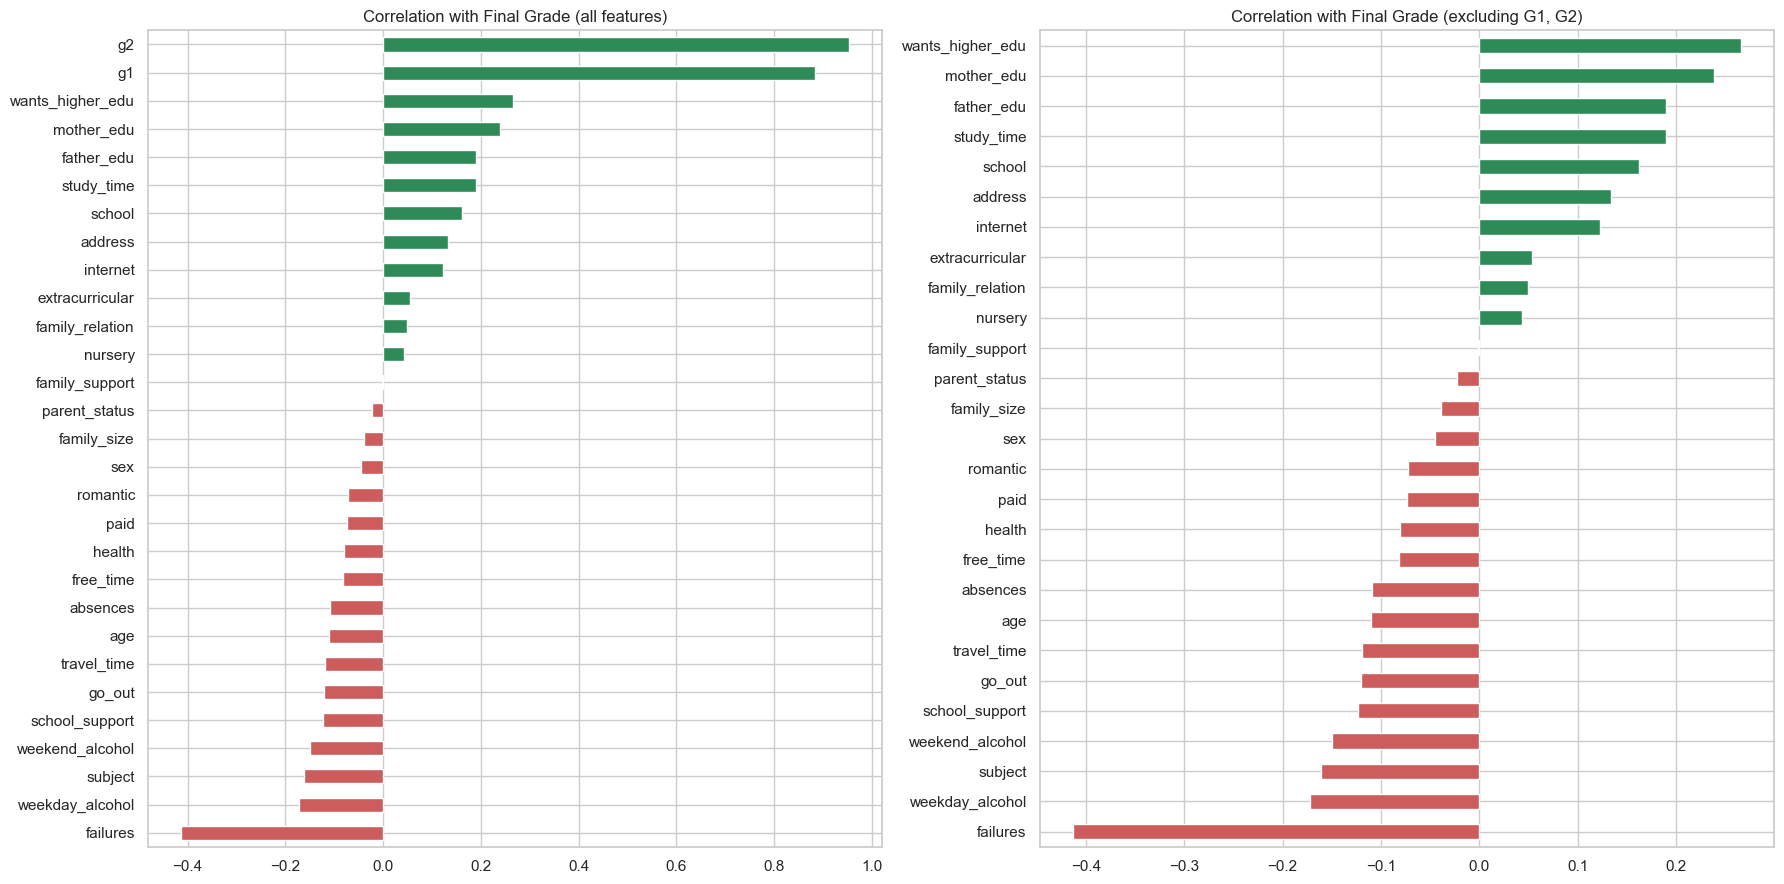

In [28]:
target = corr['g3'].drop('g3').sort_values()
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
target.plot(kind='barh', color=np.where(target > 0, 'seagreen', 'indianred'), ax=axes[0])
axes[0].set_title('Correlation with Final Grade (all features)')

no_prev = target.drop(['g1', 'g2'])
no_prev.plot(kind='barh', color=np.where(no_prev > 0, 'seagreen', 'indianred'), ax=axes[1])
axes[1].set_title('Correlation with Final Grade (excluding G1, G2)')
plt.tight_layout()
plt.show()

In [29]:
def eta_squared(col):
    groups = [g.g3.values for _, g in df.groupby(col)]
    grand = df.g3.mean()
    return sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df.g3 - grand) ** 2).sum()

print("Top 10 numeric/binary factors by |Spearman| (excluding G1, G2):")
print(no_prev.reindex(no_prev.abs().sort_values(ascending=False).index).head(10).round(3))
print("\nNominal factors, share of G3 variance explained (eta squared):")
print(pd.Series({c: eta_squared(c) for c in ['mother_job', 'father_job', 'reason', 'guardian']}).round(3))

Top 10 numeric/binary factors by |Spearman| (excluding G1, G2):
failures           -0.413
wants_higher_edu    0.266
mother_edu          0.238
father_edu          0.190
study_time          0.190
weekday_alcohol    -0.172
school              0.162
subject            -0.161
weekend_alcohol    -0.149
address             0.134
Name: g3, dtype: float64

Nominal factors, share of G3 variance explained (eta squared):
mother_job    0.029
father_job    0.013
reason        0.017
guardian      0.009
dtype: float64


**Findings**
- Excluding earlier grades, past failures (-0.41) are the strongest correlate, followed by the aim to pursue higher education (+0.27), mother's education (+0.24), father's education and study time (+0.19 each).
- Alcohol consumption (weekday -0.17, weekend -0.15) and school are next; all remaining lifestyle and family factors are weak.
- Occupation and reason for choosing the school explain under 3% of grade variance.

## 10. Unusual Performers and Outlier Detection

In [30]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

bounds = df.groupby('subject').g3.apply(iqr_bounds)
df['iqr_outlier'] = [not (bounds[s][0] <= g <= bounds[s][1]) for s, g in zip(df.subject, df.g3)]
df['z_score'] = df.groupby('subject').g3.transform(lambda s: (s - s.mean()) / s.std())

slope, intercept = np.polyfit(df.g2, df.g3, 1)
df['residual'] = df.g3 - (slope * df.g2 + intercept)
df['residual_outlier'] = (df.residual - df.residual.mean()).abs() > 3 * df.residual.std()

print("IQR bounds:", {s: tuple(round(v, 1) for v in b) for s, b in bounds.items()})
print("IQR outliers per subject:", df.groupby('subject').iqr_outlier.sum().to_dict())
print("|z| > 3 per subject:", df[df.z_score.abs() > 3].groupby('subject').size().to_dict())
print("Zero-grade students:", int(df.zero_grade.sum()))
print("Unexpected G3 given G2 (residual > 3 SD):", int(df.residual_outlier.sum()))

IQR bounds: {'Math': (-1.0, 23.0), 'Portuguese': (4.0, 20.0)}
IQR outliers per subject: {'Math': 0, 'Portuguese': 16}
|z| > 3 per subject: {'Portuguese': 16}
Zero-grade students: 53
Unexpected G3 given G2 (residual > 3 SD): 27


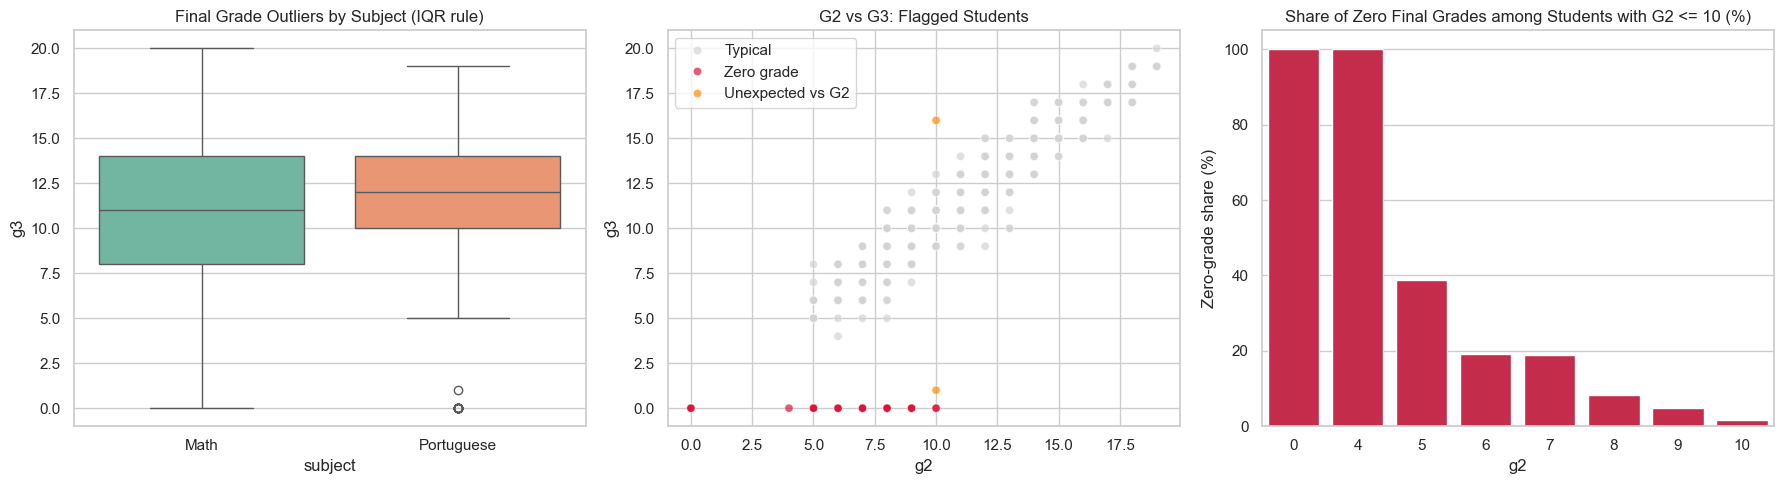

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x='subject', y='g3', hue='subject', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Final Grade Outliers by Subject (IQR rule)')

status = np.select([df.zero_grade, df.residual_outlier], ['Zero grade', 'Unexpected vs G2'], 'Typical')
sns.scatterplot(data=df, x='g2', y='g3', hue=status, hue_order=['Typical', 'Zero grade', 'Unexpected vs G2'],
                palette=['lightgrey', 'crimson', 'darkorange'], alpha=0.7, ax=axes[1])
axes[1].set_title('G2 vs G3: Flagged Students')

low_g2 = df[df.g2 <= 10]
sns.barplot(data=low_g2, x='g2', y=low_g2.zero_grade.astype(int) * 100, color='crimson', errorbar=None, ax=axes[2])
axes[2].set_title('Share of Zero Final Grades among Students with G2 <= 10 (%)')
axes[2].set_ylabel('Zero-grade share (%)')
plt.tight_layout()
plt.show()

In [32]:
profile_cols = ['g1', 'g2', 'g3', 'age', 'failures', 'study_time', 'absences', 'parent_edu']
df['group'] = np.select([df.zero_grade, df.g3 >= 18], ['Zero grade', 'Top performers (G3 >= 18)'], 'Others')
print(df.groupby('group')[profile_cols].mean().round(2))
print("\nGroup sizes:", df.group.value_counts().to_dict())
print("\nZero grade by subject and school:")
print(pd.crosstab(df[df.zero_grade].subject, df[df.zero_grade].school))
print("\nStudents with unexpected final grades (residual > 3 SD):")
df[df.residual_outlier & ~df.zero_grade][['subject', 'g1', 'g2', 'g3', 'residual', 'failures', 'absences']].round(2)

                              g1     g2     g3    age  failures  study_time  \
group                                                                         
Others                     11.20  11.38  11.72  16.70      0.24        1.96   
Top performers (G3 >= 18)  17.31  17.80  18.26  16.66      0.03        2.37   
Zero grade                  7.40   4.42   0.00  17.28      0.89        1.83   

                           absences  parent_edu  
group                                            
Others                         4.71        2.50  
Top performers (G3 >= 18)      3.66        2.77  
Zero grade                     0.00        2.21  

Group sizes: {'Others': 956, 'Zero grade': 53, 'Top performers (G3 >= 18)': 35}

Zero grade by subject and school:
school      GP  MS
subject           
Math        34   4
Portuguese   1  14

Students with unexpected final grades (residual > 3 SD):


,subject,g1,g2,g3,residual,failures,absences
456,Portuguese,10,10,16,5.99,0,0
567,Portuguese,10,10,1,-9.01,1,0


**Findings**
- Math has no IQR outliers; the 16 Portuguese outliers are all low grades, and the 53 zero-grade records are the dominant anomaly.
- Zero-grade students had falling grades (G1 7.4, G2 4.4) before dropping out, and zero recorded absences.
- Zero grades cluster in Math at school GP (34 of 38) and in Portuguese at school MS (14 of 15).
- Top performers (G3 >= 18, 35 records) enter with G1 of 17.3, so high achievement is visible from the first period.
- Only two non-zero records deviate strongly from their G2 trend, one rising to 16 and one collapsing to 1.

# Summary of Insights and Recommendations

**Key insights**
1. Previous performance dominates: G2 alone explains most of the variation in final grades, and 95% of finals fall within 2 points of G2.
2. Past failures are the strongest non-grade risk factor; students with one or more failures pass at 30-52% versus 85% for the rest.
3. Study time helps up to about 5-10 hours a week; more than that gives no extra gain.
4. Attendance matters: among active students, more absences go with lower grades (-0.24).
5. Parental education (especially the mother's), urban residence and internet access are associated with higher grades; household structure is not.
6. The wish to pursue higher education, and lower alcohol consumption, go with higher grades.
7. Gender differences are subject-specific: boys lead in Math, girls in Portuguese.
8. 53 zero-grade records reflect dropout rather than low ability and are preceded by falling grades.

**Recommendations**
- Build an early-warning system using G1/G2 and past failures; flag students with G2 <= 10 or any past failure for tutoring before the final period.
- Track dropouts separately from low achievers and follow up on students whose grades fall across periods, particularly in Math at GP and Portuguese at MS.
- Offer structured study support to students under 2 hours a week and promote moderate study (5-10 hours) rather than very long study hours.
- Set attendance monitoring with intervention at about 10+ absences.
- Support students from rural areas or without internet through lab access, device loans or offline material.
- Provide academic guidance to students whose parents have lower education levels and counsel students without higher-education aspirations.
- Run subject-specific interventions: Math support for girls, reading and writing support for boys.
- Keep extracurricular activities, since they show no negative link with grades.

**Limitations:** the data is observational, so findings show association rather than causation; the 382 students enrolled in both subjects appear in both files, absences are not recorded for dropouts, and the data comes from two schools in Portugal.